In [1]:
import pandas as pd
import numpy as np
# Ignore warnings
import warnings
warnings.filterwarnings('ignore')
# Getting access
from google.colab import drive
drive.mount('/content/drive')
# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

Mounted at /content/drive


In [2]:
df=pd.read_csv("/content/drive/MyDrive/Retail_Pulse_Project/1_Data/After_clean_retailpulse.csv")
df

,CustomerID,Age,Gender,Region,ProductCategory,AnnualIncome,PurchaseFrequency,AnnualPurchaseAmount,CustomerTenure,DiscountUsage,ReturnRate,CustomerSegment,Recency
0,204242,50,male,north,beauty,57328.90,4.0,10206.51,3.16,0.3790,0.0929,regular,115
1,299677,36,male,east,clothing,66674.05,1.0,5497.05,7.11,0.2153,0.0251,regular,56
2,240200,37,male,central,electronics,39673.95,2.0,5850.72,6.43,0.1474,0.1273,budget,72
3,232815,36,male,south,clothing,70271.46,11.0,10174.37,2.50,0.1379,0.0133,regular,30
4,508698,30,female,west,home & kitchen,67653.56,6.0,10441.58,3.21,0.0958,0.0853,regular,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
498995,359179,49,male,east,home & kitchen,64805.16,7.0,8624.35,2.85,0.3288,0.1329,regular,55
498996,465839,33,male,central,electronics,100903.39,4.0,10645.11,5.34,0.1384,0.0431,regular,66
498997,231933,33,male,central,home & kitchen,46207.75,7.0,9266.84,9.19,0.5072,0.0686,regular,1
498998,246868,51,male,south,home & kitchen,36892.09,3.0,4569.21,5.49,0.3177,0.1984,regular,66


In [3]:
X = df.drop(["AnnualPurchaseAmount", "CustomerID", "CustomerSegment"],axis=1)
y = df["AnnualPurchaseAmount"]

In [4]:
num=X.select_dtypes(include="number").columns
cat=X.select_dtypes(include="object").columns
cat # data leakage (Not use CustomerSegment)

Index(['Gender', 'Region', 'ProductCategory'], dtype='object')

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
# X_train → Gender_Male, Gender_Female
# X_test  → Gender_Male
X_train, X_test = X_train.align(
    X_test, join="left", axis=1, fill_value=0
)

In [7]:
cat_cols = ["Gender", "Region", "ProductCategory"]

X_train = pd.get_dummies(
    X_train,
    columns=cat_cols,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=cat_cols,
    drop_first=True,
    dtype=int
)

# Ensure train and test have exactly the same encoded feature columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)


In [8]:
scaler = StandardScaler()
X_train[num] = scaler.fit_transform(X_train[num])
X_test[num] = scaler.transform(X_test[num])

In [9]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [10]:
y_pred = model.predict(X_test)
y_pred

array([ 3700.66357958, 13631.6311478 , 10574.33025752, ...,
       16754.03163444, 14994.29493795, 12168.51762687])

In [11]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("RMSE:", rmse)

baseline_r2 = r2_score(y_test, y_pred)
print("Baseline R² Score:", baseline_r2)

RMSE: 5483.33478701052
Baseline R² Score: 0.6571472893362305


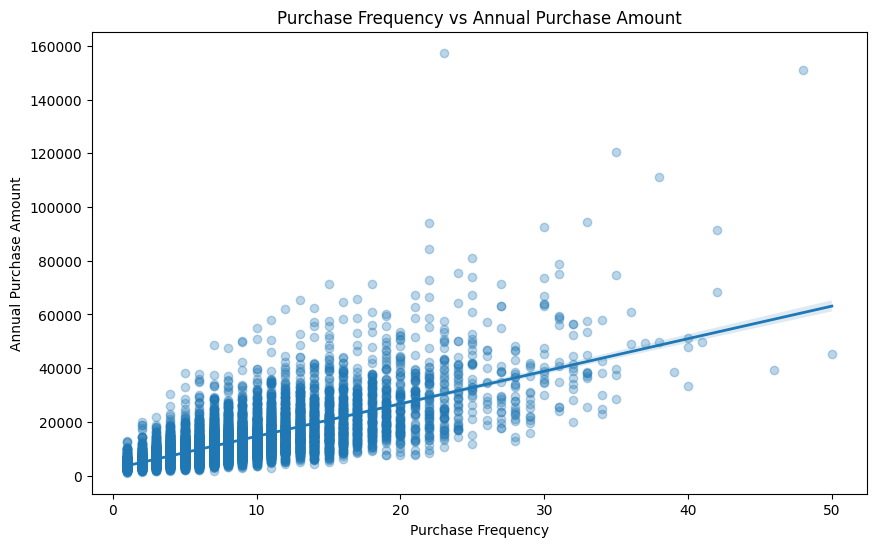

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

sample_df = df.sample(10000, random_state=42)

plt.figure(figsize=(10,6))

sns.regplot(
    data=sample_df,
    x="PurchaseFrequency",
    y="AnnualPurchaseAmount",
    scatter_kws={"alpha":0.3},
    line_kws={"linewidth":2}
)

plt.title("Purchase Frequency vs Annual Purchase Amount")
plt.xlabel("Purchase Frequency")
plt.ylabel("Annual Purchase Amount")

plt.show()

In [15]:
corr = X_train[num].corrwith(y_train)
print(corr.sort_values(key=abs, ascending=False))

PurchaseFrequency    0.705807
AnnualIncome         0.592798
Recency             -0.196438
CustomerTenure       0.178454
ReturnRate           0.119123
Age                  0.111512
DiscountUsage        0.000636
dtype: float64


In [16]:
selected_num_cols = [
    "PurchaseFrequency",
    "AnnualIncome",
    "Recency",
    "CustomerTenure",
    "ReturnRate",
    "Age"
]

In [18]:
cat_dummy_cols = [col for col in X_train.columns if col not in num]

In [19]:
selected_cols = selected_num_cols + cat_dummy_cols

X_train_selected = X_train[selected_cols]
X_test_selected = X_test[selected_cols]

In [20]:
model_selected = LinearRegression()

model_selected.fit(X_train_selected, y_train)

LinearRegression()

In [21]:
y_pred_selected = model_selected.predict(X_test_selected)

In [22]:
selected_r2 = r2_score(y_test, y_pred_selected)

print("Selected Features R²:", selected_r2)

Selected Features R²: 0.6569368313852988
